# 07｜从一条直线到非线性回归与分类

上一课的目标是一条直线，Linear 足以把它学好。这次让目标随着 x 上下弯曲：
$$y=0.5x+0.8\sin(3x)+\text{噪声}.$$
仍然训练一条直线，它会给出一条折中的斜线，曲折的部分留在残差里。
增加训练步数只能调整这条直线的位置和斜率，模型需要有表达弯曲关系的能力。

这就是本章 MLP 的用途。我们把直线模型与一个小型 MLP 放到同一份数据上，
看它们学出的函数；随后用同样的训练过程处理两类二维点，观察输出和损失怎样改变。

In [1]:
from support import ROOT, check, show, style

## 1. 生成一条带噪声的弯曲关系


    下格在 $[-2,2]$ 取240个输入点，按上面的函数生成目标，再加入标准差为0.08的高斯噪声。
    输入和目标都是一个连续数，这样的任务叫回归；每批使用 `(B,1)` 形状。
    `generator` 固定这次数据中的随机噪声，模型比较时会遇到同一组目标。

In [2]:
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.set_num_threads(1); torch.manual_seed(7); style()
generator = torch.Generator().manual_seed(7)
rx = torch.linspace(-2, 2, 240).reshape(-1, 1)
ry = 0.5 * rx + 0.8 * torch.sin(3 * rx) + 0.08 * torch.randn(240, 1, generator=generator)

## 2. 留出尚未用于更新的样本


    训练时要反复调整参数，也要知道调整后的曲线在其他点上是否合适。
    这里随机分出160个训练点、40个验证点和40个测试点。
    训练点参与梯度更新，验证点用来选参数快照，最后用测试点计算误差。

    将输入写成 $\tilde x=(x-\mu_{train})/s_{train}$，可把训练输入移到均值0、
    标准差1附近。之后模型收到新输入，也沿用训练时定下的这一变换。
    `correction=0` 对应 $s_{train}^2=N^{-1}\sum_i(x_i-\mu_{train})^2$，
    `keepdim=True` 保留 `(1,1)`，让同一组统计量广播到每份输入。

In [3]:
order = torch.randperm(len(rx), generator=generator)
rtrain, rval, rtest = order[:160], order[160:200], order[200:]
rmean = rx[rtrain].mean(dim=0, keepdim=True)
rstd = rx[rtrain].std(dim=0, keepdim=True, correction=0)
rxs = (rx - rmean) / rstd
print('样本数:', len(rtrain), len(rval), len(rtest))
print('训练均值、标准差:', rmean.item(), rstd.item())
check('训练标准化均值', rxs[rtrain].mean(), 0.)

样本数: 160 40 40
训练均值、标准差: 0.09163180738687515 1.1674494743347168
通过：训练标准化均值


### 练习 7.1：只用训练集标准化

训练输入 `[1,3]`，测试输入 `[5]`。用训练总体均值和标准差变换测试输入。

In [4]:
ex_t71_result = None

In [5]:
# 填写上一格后，运行检查。
check('测试集沿用训练统计', ex_t71_result, [3.])

待填写：测试集沿用训练统计


<details>
<summary>提示</summary>

训练均值为2、总体标准差为1；不要把测试值加入统计。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t71_train = torch.tensor([1., 3.])
ex_t71_test = torch.tensor([5.])
ex_t71_result = (ex_t71_test - ex_t71_train.mean()) / ex_t71_train.std(correction=0)
```

</details>

## 3. 线性模型的表达能力


    `nn.Linear(1,1)` 始终画出 $\hat y=wx+b$ 这条直线。
    即使相接两个无激活的线性层，展开后仍是仿射函数：
    $W_2(W_1x+b_1)+b_2=(W_2W_1)x+(W_2b_1+b_2)$。
    中间加入 Tanh 后，每个隐藏单元会得到一条经过平滑弯折的响应曲线，
    输出层再将这些响应加权组合。这里的宽度16表示有16份这样的中间响应。
    下格打印出49个 MLP 参数，包含两层的权重与偏置。

In [6]:
torch.manual_seed(7)
regression_models = {
    'Linear': nn.Linear(1, 1),
    'MLP': nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1)),
}
for name, net in regression_models.items():
    print(name, '输入输出:', (4, 1), tuple(net(rxs[:4]).shape),
          '参数量:', sum(p.numel() for p in net.parameters()))

Linear 输入输出: (4, 1) (4, 1) 参数量: 2
MLP 输入输出: (4, 1) (4, 1) 参数量: 49


## 4. MSE 从目标写到导数


    用一个数评价整条预测曲线，可以将每个点的预测误差平方后平均：
    $$L=\frac1B\sum_i(\hat y_i-y_i)^2,\qquad
      \frac{\partial L}{\partial\hat y_i}=\frac2B(\hat y_i-y_i).$$
    一项误差为正，梯度下降就推动该预测减小；误差为负，推动预测增大。
    若 $\hat y=Xw+b$，继续乘上线性层的局部导数，得到 $\nabla_wL=X^\top[2(\hat y-y)/B]$，
    $\nabla_bL=\sum_i2(\hat y_i-y_i)/B$。
    下格两个残差是−1、2，平均平方误差为2.5，预测梯度为−1、2。
    `F.mse_loss` 默认对所有输出元素求均值，本课每个样本只有一个输出，正好对应这份推导。

In [7]:
demo_pred = torch.tensor([[1.], [3.]], requires_grad=True)
demo_y = torch.tensor([[2.], [1.]])
mse = F.mse_loss(demo_pred, demo_y)
mse.backward()
analytic = 2 * (demo_pred.detach() - demo_y) / len(demo_y)
print('MSE:', mse.item(), '预测梯度:', demo_pred.grad.T)
check('MSE导数', demo_pred.grad, analytic)

MSE: 2.5 预测梯度: tensor([[-1.,  2.]])
通过：MSE导数


### 练习 7.2：数一遍 MLP 参数

网络是 Linear(3,4)→Tanh→Linear(4,2)，返回可学习参数总数。也写出各层权重、偏置形状。

In [8]:
ex_t72_result = None

In [9]:
# 填写上一格后，运行检查。
check('MLP参数量', ex_t72_result, 26)

待填写：MLP参数量


<details>
<summary>提示</summary>

第一层4×3+4，第二层2×4+2；Tanh无可学习参数。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t72_net = nn.Sequential(nn.Linear(3, 4), nn.Tanh(), nn.Linear(4, 2))
ex_t72_result = sum(p.numel() for p in ex_t72_net.parameters())
print([(name, tuple(p.shape)) for name, p in ex_t72_net.named_parameters()])
```

</details>

## 5. Adam 怎样利用梯度历史


    训练 MLP 时，不同参数会收到不同大小、不断变化的梯度。
    这里采用 Adam：为每个参数保留梯度方向的平滑记录 m，以及梯度平方的平滑记录 v，
    用它们确定更新。令当前梯度为 $g_t$，从 $m_0=v_0=0$ 开始，更新
    $$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\quad
      v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.$$
    初值为零会压低前几步的平均值；按已累计的权重做偏差校正，得到
    $\hat m_t=m_t/(1-\beta_1^t)$、$\hat v_t=v_t/(1-\beta_2^t)$，再更新
    $$\theta_t=\theta_{t-1}-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon}.$$
    PyTorch 默认 $\beta_1=0.9,\beta_2=0.999,\varepsilon=10^{-8}$。
    下格只看第一步：梯度为0.2时，校正后的 m 是0.2、v 是0.04，
    归一后的更新量接近学习率0.01，参数从1变为约0.99。整网训练对每个参数重复这一计算。

In [10]:
adam_parameter = nn.Parameter(torch.tensor(1., dtype=torch.float64))
adam_optimizer = torch.optim.Adam([adam_parameter], lr=.01)
adam_parameter.grad = torch.tensor(.2, dtype=torch.float64)
first_m = (1 - .9) * .2
first_v = (1 - .999) * .2 ** 2
expected_adam = 1 - .01 * (first_m / (1 - .9)) / (np.sqrt(first_v / (1 - .999)) + 1e-8)
adam_optimizer.step()
check('Adam第一次更新', adam_parameter, expected_adam)

通过：Adam第一次更新


## 6. 用验证集选择保存的参数


    训练开始后，参数每一步都在变化，其中某一步可能对留出的验证点拟合得最好。
    下面让两个模型各更新300次，每次使用全部160个训练点，随后计算40个验证点的 MSE。
    验证误差更低时，将当前参数存入 best_state，结束后恢复这份快照。

    `.clone()` 在这里有实际作用：快照要保存当时的数值，后续更新继续修改模型本身。
    训练循环还保留每一步的训练、验证损失，下一格会把它们画成曲线。

In [11]:
regression_history = {}
for name, net in regression_models.items():
    optimizer = torch.optim.Adam(net.parameters(), lr=0.02)
    records, best_value, best_state = [], float('inf'), None
    for epoch in range(300):
        net.train(); optimizer.zero_grad(set_to_none=True)
        loss = F.mse_loss(net(rxs[rtrain]), ry[rtrain])
        loss.backward(); optimizer.step()
        net.eval()
        with torch.no_grad():
            valid_loss = F.mse_loss(net(rxs[rval]), ry[rval]).item()
        records.append((loss.item(), valid_loss))
        if valid_loss < best_value:
            best_value = valid_loss
            best_state = {key: value.clone() for key, value in net.state_dict().items()}
    net.load_state_dict(best_state)
    regression_history[name] = np.asarray(records)

## 7. 看误差，也看学出的函数


    左图比较验证 MSE，右图直接画最终预测函数。在这份固定种子和划分下，
    测试 MSE 约为线性模型0.29、MLP 0.02，图中可以找到误差差异的来源：
    直线穿过了数据的大致趋势，MLP 还能跟随中间的起伏。

    这组输出让表达能力有了具体含义。若直线的损失已稳定，再重复同一更新，
    仍只能得到另一条直线；增加非线性隐藏响应，才改变了可画出的函数形状。

Linear 测试MSE: 0.29287
MLP 测试MSE: 0.02163


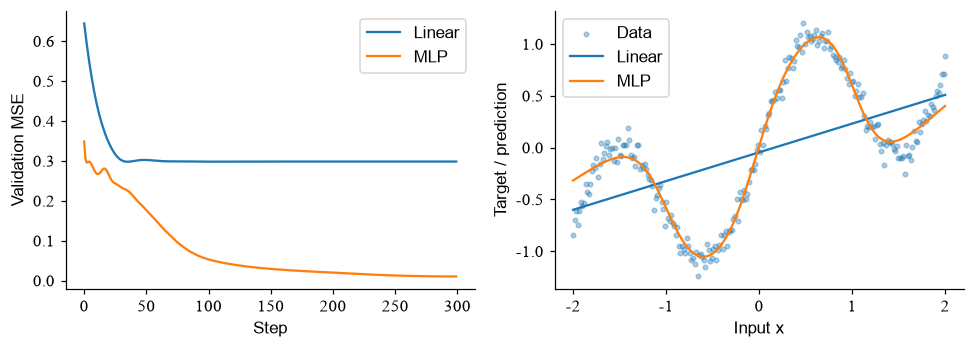

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
axes[1].scatter(rx[:, 0], ry[:, 0], s=9, alpha=.35, label='Data')
for name, net in regression_models.items():
    with torch.no_grad():
        predictions = net(rxs)
        test_mse = F.mse_loss(predictions[rtest], ry[rtest]).item()
    print(name, '测试MSE:', round(test_mse, 5))
    axes[0].plot(regression_history[name][:, 1], label=name)
    axes[1].plot(rx[:, 0], predictions[:, 0], label=name)
axes[0].set(xlabel='Step', ylabel='Validation MSE'); axes[0].legend()
axes[1].set(xlabel='Input x', ylabel='Target / prediction'); axes[1].legend()
fig.tight_layout(); show(fig)

### 练习 7.3：MSE 通过线性层回传

$X=[[1,2],[3,4]],w=[1,0],y=[2,2]$，无偏置，采用均方误差。手算返回 $\nabla_wL$。

In [13]:
ex_t73_result = None

In [14]:
# 填写上一格后，运行检查。
check('回传到权重', ex_t73_result, [2., 2.])

待填写：回传到权重


<details>
<summary>提示</summary>

先算预测 `[1,3]`，再用 `X.T @ (2*error/B)`。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t73_X = torch.tensor([[1., 2.], [3., 4.]])
ex_t73_w = torch.tensor([1., 0.])
ex_t73_error = ex_t73_X @ ex_t73_w - torch.tensor([2., 2.])
ex_t73_result = ex_t73_X.T @ (2 * ex_t73_error / 2)
```

</details>

## 8. 分类从 logits 得到概率


    把目标换成类别后，单个连续预测值就不够用了。
    网络为每个样本输出 $C$ 个实数 $z_1,\ldots,z_C$，每类一个分数，称为 logits。
    用 Softmax 将这组相对分数转换成总和为1的概率：
    $$p_k=\frac{e^{z_k}}{\sum_j e^{z_j}}.$$
    下格的 `[1,2,-1]` 变成约 `[0.259,0.705,0.035]`，第二类概率最高。
    分母由全部类别共同决定，提高一类的分数也会降低其他类的概率。
    计算时同时减去最大 logit，分子分母都约去同一因子，概率保持相同，指数数值则更稳。

In [15]:
logits_demo = torch.tensor([[1., 2., -1.]], dtype=torch.float64)
shifted = logits_demo - logits_demo.max(dim=1, keepdim=True).values
probabilities = shifted.exp() / shifted.exp().sum(dim=1, keepdim=True)
print('logits:', logits_demo, '概率:', probabilities)
check('概率归一', probabilities.sum(dim=1), [1.])
check('手写与torch.softmax', probabilities, torch.softmax(logits_demo, dim=1))

logits: tensor([[ 1.,  2., -1.]], dtype=torch.float64) 概率: tensor([[0.2595, 0.7054, 0.0351]], dtype=torch.float64)
通过：概率归一
通过：手写与torch.softmax


## 9. 将正确类别的概率写成损失


    如果真实类别是第二类，刚才的0.705就是模型分给正确答案的概率。
    希望这个概率增大，可以最小化它的负对数。
    真类别编号记为 $t$，用 $y_k=\mathbf1[k=t]$ 表示对应的 one-hot 向量，单样本交叉熵为
    $$L=-\log p_t=-z_t+\log\sum_j e^{z_j}.$$
    对 $z_k$ 求导：$-z_t$ 给出 $-y_k$；对数项给出
    $e^{z_k}/\sum_j e^{z_j}=p_k$，所以
    $\partial L/\partial z_k=p_k-y_k$。批平均后再除以 $B$。
    正确类的梯度为 $p_t-1<0$，其他类的梯度为正。
    沿 logits 的负梯度移动，方向就是提高正确类的分数、压低其余分数。
    `F.cross_entropy(logits, targets)` 把这些运算合在内部，输入直接用 logits，
    目标则是一批类别编号，形状 `(B,)`、类型 `long`。

In [16]:
ce_logits = torch.tensor([[1., 2., -1.], [0., 1., 0.]], requires_grad=True)
ce_targets = torch.tensor([1, 0], dtype=torch.long)
ce = F.cross_entropy(ce_logits, ce_targets)
ce.backward()
ce_expected = (ce_logits.detach().softmax(dim=1) - F.one_hot(ce_targets, 3)) / 2
print('CE:', ce.item(), '\nlogit梯度:\n', ce_logits.grad)
check('批平均交叉熵梯度', ce_logits.grad, ce_expected)

CE: 0.9502283930778503 
logit梯度:
 tensor([[ 0.1297, -0.1473,  0.0176],
        [-0.3940,  0.2881,  0.1060]])
通过：批平均交叉熵梯度


### 练习 7.4：相同 logits 的交叉熵

两个样本、三个类别，所有 logits 都是0，真类别为 `[0,2]`。求批平均 CE，并返回 logits 的梯度。

In [17]:
ex_t74_loss, ex_t74_grad = None, None

In [18]:
# 填写上一格后，运行检查。
check('均匀概率CE', ex_t74_loss, np.log(3.))
check('CE梯度', ex_t74_grad, [[-1/3, 1/6, 1/6], [1/6, 1/6, -1/3]])

待填写：均匀概率CE
待填写：CE梯度


<details>
<summary>提示</summary>

每类概率为1/3；每行梯度为 `(p-one_hot)/2`。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t74_z = torch.zeros(2, 3, requires_grad=True)
ex_t74_loss = F.cross_entropy(ex_t74_z, torch.tensor([0, 2]))
ex_t74_loss.backward()
ex_t74_grad = ex_t74_z.grad.clone()
```

</details>

## 10. 二维分类：线性边界与非线性边界


    现在让两组相对的象限属于同一类：对二维点 $x=(x_1,x_2)$，
    同号的两个坐标归为类别1，异号归为类别0。这是连续样本上的 XOR 结构。
    用一条直线切开平面，总有相对的一组象限分不对。

    线性模型的两个 logits 相减仍是仿射函数，预测由 $z_1-z_0$ 的正负决定，
    因此类别边界仍是一条直线。下面的 MLP 使用16个 Tanh 隐藏响应，
    将输入变为新特征后再分类，允许边界弯曲。

In [19]:
cg = torch.Generator().manual_seed(71)
cx = torch.rand(320, 2, generator=cg) * 2 - 1
cy = (cx[:, 0] * cx[:, 1] > 0).long()
ci = torch.randperm(len(cx), generator=cg)
ctrain, cval, ctest = ci[:220], ci[220:270], ci[270:]
torch.manual_seed(71)
classifiers = {'Linear': nn.Linear(2, 2),
               'MLP': nn.Sequential(nn.Linear(2, 16), nn.Tanh(), nn.Linear(16, 2))}
print('输入:', cx.shape, '标签:', cy.shape, cy.dtype)

输入: torch.Size([320, 2]) 标签: torch.Size([320]) torch.int64


## 11. 把回归循环用于类别预测


    从清梯度到参数更新，这个循环与刚才的回归循环相同。
    变化发生在模型末端：输出是 `(B,2)` logits，交叉熵将它们与 `(B,)` 类别编号比较。
    `argmax(dim=1)` 取每行分数最大的类别，便得到可与标签直接比较的 `(B,)` 预测。

    两个模型各更新250次，并按同一验证集上的 CE 保存参数。
    测试准确率表示50个留出测试点中预测正确的比例；下一幅边界图会展示这些点落在哪里。

In [20]:
for name, net in classifiers.items():
    optimizer = torch.optim.Adam(net.parameters(), lr=.03)
    best_value, best_state = float('inf'), None
    for epoch in range(250):
        net.train(); optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(net(cx[ctrain]), cy[ctrain])
        loss.backward(); optimizer.step()
        net.eval()
        with torch.no_grad():
            value = F.cross_entropy(net(cx[cval]), cy[cval]).item()
        if value < best_value:
            best_value = value
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
    net.load_state_dict(best_state)
    with torch.no_grad():
        accuracy = (net(cx[ctest]).argmax(1) == cy[ctest]).float().mean().item()
    print(name, '验证CE:', round(best_value, 4), '测试准确率:', round(accuracy, 3))

Linear 验证CE: 0.6718 测试准确率: 0.6


MLP 验证CE: 0.0264 测试准确率: 1.0


### 练习 7.5：取出预测类别

logits 是 `[[2,1,-1],[0,3,4]]`，真类别 `[0,1]`，返回分类准确率。

In [21]:
ex_t75_result = None

In [22]:
# 填写上一格后，运行检查。
check('准确率', ex_t75_result, 0.5)

待填写：准确率


<details>
<summary>提示</summary>

`argmax(dim=1)` 后与目标逐项比较，转float求均值。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t75_z = torch.tensor([[2., 1., -1.], [0., 3., 4.]])
ex_t75_targets = torch.tensor([0, 1])
ex_t75_result = (ex_t75_z.argmax(1) == ex_t75_targets).float().mean()
```

</details>

## 12. 画决策边界，检查模型学到的形状


    下格在平面上铺一张90×90网格，将坐标排成8100行二维输入。
    模型为每行预测类别，再将结果排回方格，背景色就显出了模型的分类区域。
    散点颜色是真实类别；散点与所在背景颜色不同，就是一个错例。

    同样的训练步骤，线性模型画出直线边界，MLP 则能分出相对的象限。
    把本章两幅结果图并排看，回归中的弯曲拟合和分类中的弯曲边界来自同一个改变：
    在两层线性变换之间加入非线性激活。

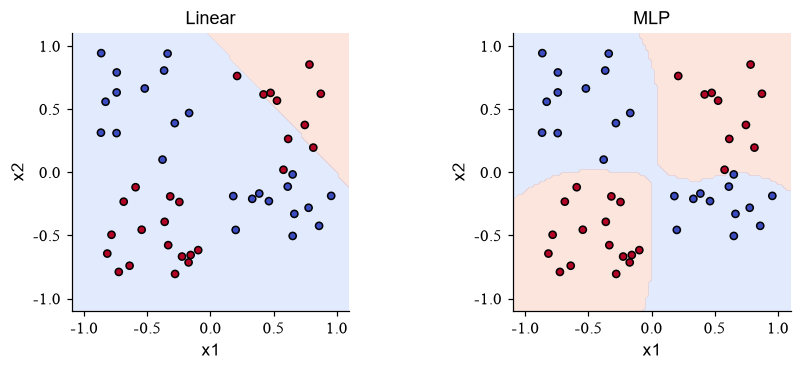

In [23]:
axis = torch.linspace(-1.1, 1.1, 90)
gx, gy = torch.meshgrid(axis, axis, indexing='xy')
grid = torch.stack([gx.flatten(), gy.flatten()], dim=1)
fig, axes = plt.subplots(1, 2, figsize=(8.3, 3.5))
for ax, (name, net) in zip(axes, classifiers.items()):
    with torch.no_grad():
        labels = net(grid).argmax(1).reshape(gx.shape)
    ax.contourf(gx, gy, labels, levels=[-.5, .5, 1.5], cmap='coolwarm', alpha=.25)
    ax.scatter(cx[ctest, 0], cx[ctest, 1], c=cy[ctest], cmap='coolwarm', edgecolors='k', s=22)
    ax.set(title=name, xlabel='x1', ylabel='x2', aspect='equal')
fig.tight_layout(); show(fig)

[打开实时训练实验](../interactive/index.html#training)：保留 XOR 数据，把隐藏层数设为0，
训练并观察边界；随后改为带 Tanh 的隐藏层，重新初始化并训练。
比较验证点、边界形状和损失曲线。固定结构后，只改变学习率，观察同样20步内损失怎样移动。

### 练习 7.6：验证集选择参数

三个 epoch 的验证损失依次是 `[.7,.4,.5]`，相应参数快照是 `[1,2,3]`。返回应选的参数值。

In [24]:
ex_t76_result = None

In [25]:
# 填写上一格后，运行检查。
check('验证集选模', ex_t76_result, 2.)

待填写：验证集选模


<details>
<summary>提示</summary>

选择验证损失最小的下标，再从同一下标读取参数快照。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t76_val = np.array([.7, .4, .5])
ex_t76_snapshots = np.array([1., 2., 3.])
ex_t76_result = ex_t76_snapshots[ex_t76_val.argmin()]
```

</details>

## 13. 接到 NTU 的实际回归作业

可选的本地 NTU 作业 `HW05_Regression.ipynb`
用游戏特征预测 Steam 游戏的 Metacritic 分数。输入从本章的一列 x 变成多列游戏特征，
输出仍是一个连续评分，主干形状因此变成 `(B,D)→(B,1)`。
Dataset 的 `__getitem__` 决定一份游戏数据究竟含哪些数值，模型第一层必须接得上这个 D。

阅读时沿着一份游戏记录追到评分损失，标出中途的形状。
类别特征编码、缺失值处理与数值缩放都发生在这条数据流上，
而本章的正向、MSE、反传和更新可以直接成为理解训练部分的起点。

## 带着问题读原文

[PyTorch：CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)

找到输入和类别编号目标的形状。把文档中的负对数似然展开成 `-z_t+logsumexp(z)`，对照本课推导，说明批平均怎样进入梯度。

**单变量实验：**只把隐藏宽度从16改成4，保留划分和训练设置；同时比较验证误差与边界形状。